# Cleaning the OpenAQ table

## Setup

In [1]:
import os
os.chdir("/home/jovyan/work")

In [2]:
from pyspark.sql import SparkSession, functions as F
import pandas as pd
import matplotlib.pyplot as plt

spark = (
    SparkSession.builder
    .appName("clean_openaq_notebook")
    .config("spark.driver.memory", "6g")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)
print("driver.memory:", spark.sparkContext.getConf().get("spark.driver.memory", "NOT SET"))
spark

driver.memory: 6g


## Step 1: load the raw table

In [3]:
df = spark.read.parquet("data/processed/openaq_raw")
start_count = df.count()
print("Rows read:", start_count)
df.printSchema()
df.show(20)

Rows read: 10115729
root
 |-- location_id: integer (nullable = true)
 |-- sensors_id: integer (nullable = true)
 |-- location: string (nullable = true)
 |-- datetime: string (nullable = true)
 |-- lat: double (nullable = true)
 |-- lon: double (nullable = true)
 |-- parameter: string (nullable = true)
 |-- units: string (nullable = true)
 |-- value: double (nullable = true)
 |-- _corrupt_record: string (nullable = true)
 |-- year: integer (nullable = true)

+-----------+----------+-----------------+--------------------+-----------------+-----------------+---------+-----+------------------+---------------+----+
|location_id|sensors_id|         location|            datetime|              lat|              lon|parameter|units|             value|_corrupt_record|year|
+-----------+----------+-----------------+--------------------+-----------------+-----------------+---------+-----+------------------+---------------+----+
|    3086825|  10792391|Palaiseau-3056771|2024-10-27T01:00:...|48.7192

## Step 2: explore temporal coverage

,year,count
0,2018,1137525
1,2019,1327401
2,2020,1271665
3,2021,498206
4,2022,586440
5,2023,1404687
6,2024,1092447
7,2025,1378600
8,2026,1418758


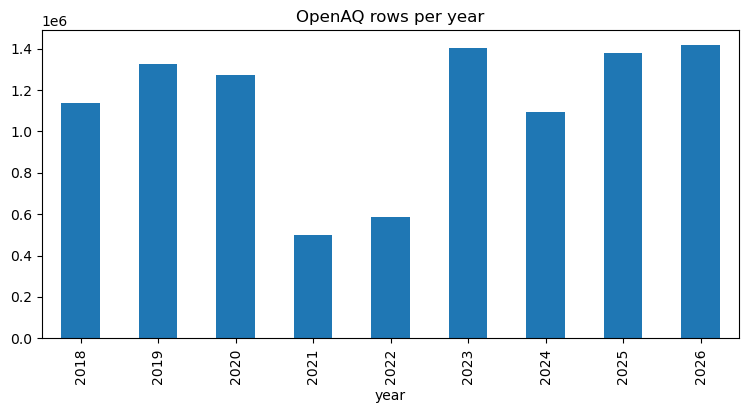

In [4]:
rows_per_year = df.groupBy("year").count().orderBy("year").toPandas()
rows_per_year.plot(kind="bar", x="year", y="count", legend=False, title="OpenAQ rows per year", figsize=(9, 4))
rows_per_year

In [5]:
# A station with no data in early years would make a 2018-vs-2024 comparison
# misleading, so we check station *counts* per year, not just row counts.
stations_per_year = (
    df.groupBy("year")
    .agg(F.countDistinct("location_id").alias("distinct_stations"))
    .orderBy("year")
)
stations_per_year.show(20)

+----+-----------------+
|year|distinct_stations|
+----+-----------------+
|2018|               83|
|2019|               74|
|2020|               74|
|2021|               73|
|2022|               72|
|2023|               71|
|2024|               91|
|2025|               91|
|2026|               95|
+----+-----------------+



## Step 3: drop corrupt rows

In [6]:
df = df.filter(F.col("_corrupt_record").isNull())
after_corrupt = df.count()
print("Dropped for being corrupt/unparseable:", start_count - after_corrupt)
print("Rows remaining:", after_corrupt)

Dropped for being corrupt/unparseable: 0
Rows remaining: 10115729


## Step 4: restrict to our target pollutants

In [7]:
CORE_POLLUTANTS = ["pm25", "pm10", "no2", "o3"]

df.filter(~F.col("parameter").isin(CORE_POLLUTANTS)).groupBy("parameter").count().show()

df = df.filter(F.col("parameter").isin(CORE_POLLUTANTS))
after_parameter_filter = df.count()
print("Dropped rows outside our 4 target pollutants:", after_corrupt - after_parameter_filter)
print("Rows remaining:", after_parameter_filter)

+----------------+------+
|       parameter| count|
+----------------+------+
|             so2|320210|
|           um003|131701|
|              no|396945|
|     temperature|131701|
|             pm1|131563|
|relativehumidity|131646|
|              co|156642|
+----------------+------+

Dropped rows outside our 4 target pollutants: 1400408
Rows remaining: 8715321


## Step 4b: null values per pollutant
Right now each row is one station+hour+**one** pollutant (long format), so this checks whether the actual `value` for that pollutant reading is ever null -- a different question from "does this station have a sensor for this pollutant at all" (that's Step 11b, after the pivot).

In [8]:
null_check = (
    df.groupBy("parameter")
    .agg(
        F.count(F.lit(1)).alias("rows"),
        F.sum(F.col("value").isNull().cast("int")).alias("null_value_count"),
    )
    .orderBy("parameter")
)
null_check.show()

+---------+-------+----------------+
|parameter|   rows|null_value_count|
+---------+-------+----------------+
|      no2|3079616|               0|
|       o3|2234750|               0|
|     pm10|2007549|               0|
|     pm25|1393406|               0|
+---------+-------+----------------+



## Step 5: check unit consistency

In [9]:
units_per_parameter = (
    df.groupBy("parameter")
    .agg(F.countDistinct("units").alias("distinct_units"))
    .orderBy(F.desc("distinct_units"))
)
units_per_parameter.show()
print("Pollutants with more than one unit in use:", units_per_parameter.filter(F.col("distinct_units") > 1).count())

+---------+--------------+
|parameter|distinct_units|
+---------+--------------+
|     pm25|             1|
|     pm10|             1|
|      no2|             1|
|       o3|             1|
+---------+--------------+

Pollutants with more than one unit in use: 0


## Step 6: parse the timestamp into real UTC

In [10]:
df = df.withColumn("datetime_utc", F.to_timestamp("datetime", "yyyy-MM-dd'T'HH:mm:ssXXX"))
df.select("datetime", "datetime_utc").show(5, truncate=False)

+-------------------------+-------------------+
|datetime                 |datetime_utc       |
+-------------------------+-------------------+
|2024-10-27T01:00:00+02:00|2024-10-26 23:00:00|
|2024-02-15T01:00:00+01:00|2024-02-15 00:00:00|
|2024-10-27T02:00:00+02:00|2024-10-27 00:00:00|
|2024-02-15T02:00:00+01:00|2024-02-15 01:00:00|
|2024-10-27T02:00:00+01:00|2024-10-27 01:00:00|
+-------------------------+-------------------+
only showing top 5 rows



In [11]:
df = df.filter(F.col("datetime_utc").isNotNull())
after_timestamp = df.count()
print("Dropped for an unparseable datetime:", after_parameter_filter - after_timestamp)
print("Rows remaining:", after_timestamp)

Dropped for an unparseable datetime: 0
Rows remaining: 8715321


## Step 7: drop impossible values

In [12]:
negative_rows = df.filter(F.col("value") < 0)
print("Example rows with a negative value:")
negative_rows.select("location_id", "parameter", "value", "datetime_utc").show(5)

Example rows with a negative value:
+-----------+---------+-----+-------------------+
|location_id|parameter|value|       datetime_utc|
+-----------+---------+-----+-------------------+
|       4075|     pm25| -0.2|2024-02-03 08:00:00|
|       4075|     pm25| -1.5|2024-02-03 09:00:00|
|       4075|     pm25| -1.8|2024-02-03 10:00:00|
|       4075|     pm25| -0.6|2024-02-03 11:00:00|
|       4075|     pm25| -0.5|2024-02-03 12:00:00|
+-----------+---------+-----+-------------------+
only showing top 5 rows



In [13]:
df = df.filter(F.col("value") >= 0)
after_value = df.count()
print("Dropped for a negative pollutant value:", after_timestamp - after_value)
print("Rows remaining:", after_value)

Dropped for a negative pollutant value: 56759
Rows remaining: 8658562


## Step 8: look at the real distribution per pollutant


In [14]:
(
    df.groupBy("parameter", "units")
    .agg(
        F.count(F.lit(1)).alias("rows"),
        F.round(F.min("value"), 1).alias("min"),
        F.round(F.expr("percentile_approx(value, 0.5)"), 1).alias("p50_median"),
        F.round(F.expr("percentile_approx(value, 0.95)"), 1).alias("p95"),
        F.round(F.expr("percentile_approx(value, 0.99)"), 1).alias("p99"),
        F.round(F.max("value"), 1).alias("max"),
    )
    .orderBy("parameter")
    .show(truncate=False)
)

+---------+-----+-------+---+----------+----+-----+------+
|parameter|units|rows   |min|p50_median|p95 |p99  |max   |
+---------+-----+-------+---+----------+----+-----+------+
|no2      |µg/m³|3075327|0.0|16.2      |61.9|89.1 |1625.7|
|o3       |µg/m³|2209087|0.0|53.5      |99.8|129.1|363.1 |
|pm10     |µg/m³|1993169|0.0|14.1      |40.5|62.2 |1654.7|
|pm25     |µg/m³|1380979|0.0|7.0       |25.7|40.9 |1560.1|
+---------+-----+-------+---+----------+----+-----+------+



## Step 9: drop impossible coordinates

In [15]:
df = df.filter(F.col("lat").between(-90, 90) & F.col("lon").between(-180, 180))
after_coords = df.count()
print("Dropped for impossible coordinates:", after_value - after_coords)
print("Rows remaining:", after_coords)

Dropped for impossible coordinates: 0
Rows remaining: 8658562


## Step 10: drop duplicates

In [16]:
df = df.dropDuplicates(["location_id", "sensors_id", "datetime_utc"])
after_dedup = df.count()
print("Dropped as duplicates (same station+sensor+UTC hour):", after_coords - after_dedup)
print("Rows remaining:", after_dedup)

Dropped as duplicates (same station+sensor+UTC hour): 0
Rows remaining: 8658562


## Step 11: pivot long -> wide

In [17]:
wide = (
    df.groupBy("location_id", "datetime_utc")
    .pivot("parameter")
    .agg(F.first("value"))
)
wide_count = wide.count()
print("Rows after pivoting to wide format (one row per station+hour):", wide_count)
wide.printSchema()
wide.show(5)

Rows after pivoting to wide format (one row per station+hour): 4207002
root
 |-- location_id: integer (nullable = true)
 |-- datetime_utc: timestamp (nullable = true)
 |-- no2: double (nullable = true)
 |-- o3: double (nullable = true)
 |-- pm10: double (nullable = true)
 |-- pm25: double (nullable = true)

+-----------+-------------------+-----+----+-----+----+
|location_id|       datetime_utc|  no2|  o3| pm10|pm25|
+-----------+-------------------+-----+----+-----+----+
|       2681|2018-01-06 01:00:00| 56.5|NULL| 28.3|NULL|
|       2681|2018-01-12 13:00:00| 72.0|NULL| 45.0|NULL|
|       2681|2018-01-14 23:00:00| 33.5|NULL|26.35|NULL|
|       2681|2018-01-22 00:00:00| 25.5|NULL| 1.25|NULL|
|       2681|2018-02-01 15:00:00|68.75|NULL|19.48|NULL|
+-----------+-------------------+-----+----+-----+----+
only showing top 5 rows



In [18]:
# Sanity check: the groupBy should make this impossible to get wrong, but worth
# confirming directly rather than assuming.
distinct_station_hours = wide.select("location_id", "datetime_utc").distinct().count()
print("Rows in wide table:", wide_count)
print("Distinct (location_id, datetime_utc) pairs:", distinct_station_hours)
print("One row per station-hour?", wide_count == distinct_station_hours)

Rows in wide table: 4207002
Distinct (location_id, datetime_utc) pairs: 4207002
One row per station-hour? True


## Step 11b: check pollutant coverage across all stations

In [19]:
# Overall: what fraction of all station-hours actually have a reading for each pollutant?
coverage = wide.agg(
    *[F.round(F.count(c) / F.lit(wide_count) * 100, 1).alias(f"{c}_measured_pct") for c in CORE_POLLUTANTS]
)
coverage.show()

+-----------------+-----------------+----------------+---------------+
|pm25_measured_pct|pm10_measured_pct|no2_measured_pct|o3_measured_pct|
+-----------------+-----------------+----------------+---------------+
|             32.8|             47.4|            73.1|           52.5|
+-----------------+-----------------+----------------+---------------+



In [20]:
# Per-station: how many stations have NO sensor at all for a given pollutant
# (like station 4092 and NO2), versus just some missing hours?
station_has_sensor = wide.groupBy("location_id").agg(
    *[F.max(F.col(c).isNotNull().cast("int")).alias(f"has_{c}") for c in CORE_POLLUTANTS]
)
n_stations = station_has_sensor.count()
for c in CORE_POLLUTANTS:
    n_with = station_has_sensor.filter(F.col(f"has_{c}") == 1).count()
    print(f"{c}: {n_with} of {n_stations} stations have at least one reading ({n_stations - n_with} have none at all)")

pm25: 69 of 123 stations have at least one reading (54 have none at all)
pm10: 72 of 123 stations have at least one reading (51 have none at all)
no2: 83 of 123 stations have at least one reading (40 have none at all)
o3: 56 of 123 stations have at least one reading (67 have none at all)


## Step 11c: how many stations have ALL 4 pollutants?

In [21]:
pollutant_counts = station_has_sensor.withColumn(
    "num_pollutants_measured",
    F.col("has_pm25") + F.col("has_pm10") + F.col("has_no2") + F.col("has_o3"),
)
pollutant_counts.groupBy("num_pollutants_measured").count().orderBy("num_pollutants_measured").show()

stations_with_all_4 = pollutant_counts.filter(F.col("num_pollutants_measured") == 4).count()
print(f"Stations with ALL 4 pollutants: {stations_with_all_4} of {n_stations}")

+-----------------------+-----+
|num_pollutants_measured|count|
+-----------------------+-----+
|                      1|   36|
|                      2|   37|
|                      3|   30|
|                      4|   20|
+-----------------------+-----+

Stations with ALL 4 pollutants: 20 of 123


## Step 11e: pollutant coverage by year

In [22]:
coverage_by_year = (
    wide.withColumn("year", F.year("datetime_utc"))
    .groupBy("year")
    .agg(
        F.count(F.lit(1)).alias("rows"),
        *[F.count(c).alias(f"{c}_count") for c in CORE_POLLUTANTS],
    )
)
for c in CORE_POLLUTANTS:
    coverage_by_year = coverage_by_year.withColumn(f"{c}_pct", F.round(F.col(f"{c}_count") / F.col("rows") * 100, 1))

coverage_by_year = coverage_by_year.select("year", "rows", *[f"{c}_pct" for c in CORE_POLLUTANTS]).orderBy("year")
coverage_by_year.show()

+----+------+--------+--------+-------+------+
|year|  rows|pm25_pct|pm10_pct|no2_pct|o3_pct|
+----+------+--------+--------+-------+------+
|2018|512889|    25.1|    53.8|   74.2|  54.0|
|2019|589631|    25.9|    53.4|   76.3|  54.9|
|2020|575724|    22.3|    53.9|   75.7|  53.7|
|2021|248083|    23.6|    46.6|   72.8|  51.4|
|2022|282705|    28.2|    44.2|   74.9|  52.5|
|2023|467132|    40.6|    51.1|   75.9|  56.1|
|2024|424917|    39.7|    46.3|   72.8|  53.8|
|2025|579370|    38.3|    37.5|   71.6|  48.2|
|2026|526551|    48.0|    37.7|   64.3|  48.3|
+----+------+--------+--------+-------+------+



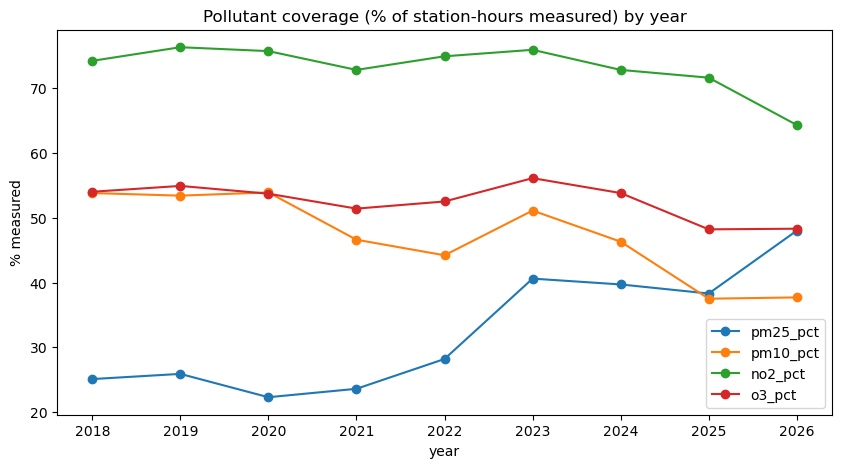

In [23]:
coverage_by_year_pd = coverage_by_year.toPandas().set_index("year")
coverage_by_year_pd[[f"{c}_pct" for c in CORE_POLLUTANTS]].plot(
    figsize=(10, 5), marker="o", title="Pollutant coverage (% of station-hours measured) by year"
)
plt.ylabel("% measured")
plt.show()

## Step 12: visualize the full cleaning funnel

,step,rows
0,raw,10115729
1,drop corrupt,10115729
2,4 target pollutants,8715321
3,parse timestamp,8715321
4,drop negative,8658562
5,drop bad coords,8658562
6,drop duplicates,8658562
7,pivoted (wide),4207002


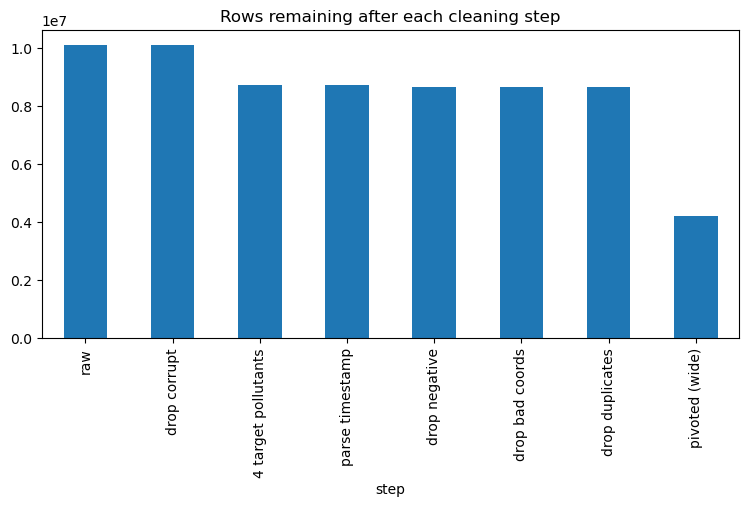

In [24]:
steps = pd.DataFrame({
    "step": ["raw", "drop corrupt", "4 target pollutants", "parse timestamp", "drop negative", "drop bad coords", "drop duplicates", "pivoted (wide)"],
    "rows": [start_count, after_corrupt, after_parameter_filter, after_timestamp, after_value, after_coords, after_dedup, wide_count],
})
steps.plot(kind="bar", x="step", y="rows", legend=False, title="Rows remaining after each cleaning step", figsize=(9, 4))
steps

## Step 13: save the cleaned table

In [ ]:
OUT_PATH = "data/processed/openaq_clean"
wide.coalesce(8).write.mode("overwrite").parquet(OUT_PATH)
print(f"Saved to {OUT_PATH}")
print("Summary: started with", start_count, "rows, ended with", wide_count, "station-hours")